#DECISION TREE


## IMPORTS AND SETUP

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    GITHUB_USER = "SinghSahiljit44"  # Es. sahiljit
    REPO_NAME = "Weather_forecasting"
    REPO_URL = f"https://github.com/{GITHUB_USER}/{REPO_NAME}.git"

    # Clona la repository se non è già stata clonata nella sessione
    if not os.path.exists(REPO_NAME):
        !git clone {REPO_URL}

    # Cambia la directory di lavoro nella root del progetto
    os.chdir(REPO_NAME)

    # Installa le dipendenze necessarie nell'ambiente di Colab
    %pip install -q -r requirements.txt

    PROJECT_ROOT = Path.cwd()
else:
    # --- CONFIGURAZIONE LOCALE  ---
    PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
    os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print(f" [OK] Ambiente rilevato: {'Google Colab' if IN_COLAB else 'Locale'}")
print(f" [OK] Directory di lavoro impostata a: {Path.cwd()}")

Cloning into 'Weather_forecasting'...
remote: Enumerating objects: 279, done.
remote: Counting objects: 100% (279/279), done.
remote: Compressing objects: 100% (215/215), done.
remote: Total 279 (delta 128), reused 206 (delta 57), pack-reused 0 (from 0)
Receiving objects: 100% (279/279), 8.00 MiB | 30.67 MiB/s, done.
Resolving deltas: 100% (128/128), done.
 [OK] Ambiente rilevato: Google Colab
 [OK] Directory di lavoro impostata a: /content/Weather_forecasting


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import src.utils.metrics as metrics

from sklearn.tree import DecisionTreeRegressor
from src.data.preprocessing import get_split

## DATASET

In [3]:
split = get_split()
features = split.get_features()

# Temperature targets
split.define_target("t2m_mean")
(X_train, yt_train), (X_val, yt_val), (X_test, yt_test) = split.get(features)

# Precipitation targets
split.define_target("tp_mm")
(_, yp_train), (_, yp_val), (_, yp_test) = split.get(features)

# Combine temperature and precipitation targets
y_train = pd.concat({"t2m_mean": yt_train, "tp_mm": yp_train}, axis=1)
y_val   = pd.concat({"t2m_mean": yt_val, "tp_mm": yp_val}, axis=1)
y_test  = pd.concat({"t2m_mean": yt_test, "tp_mm": yp_test}, axis=1)

print("Dataset shapes:")
print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape} | y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape} | y_test:  {y_test.shape}")

Dataset shapes:
X_train: (10168, 26) | y_train: (10168, 60)
X_val:   (1431, 26) | y_val:   (1431, 60)
X_test:  (1430, 26) | y_test:  (1430, 60)


## TRAIN BASIC DT WITH NOTHING

In [4]:
model = DecisionTreeRegressor(
    criterion="squared_error",
    random_state=42
)

model.fit(X_train, y_train)

print(f"Tree depth: {model.get_depth()}")
print(f"Number of leaves: {model.get_n_leaves()}")

Tree depth: 42
Number of leaves: 10168


NOTE: Super overfitted! The number of leaves is equal to the number of training examples!

In [5]:
def predict_df(model, X, y):
    return pd.DataFrame(
        model.predict(X),
        index=y.index,
        columns=y.columns
    )

y_train_pred = predict_df(model, X_train, y_train)
y_val_pred   = predict_df(model, X_val, y_val)
y_test_pred  = predict_df(model, X_test, y_test)

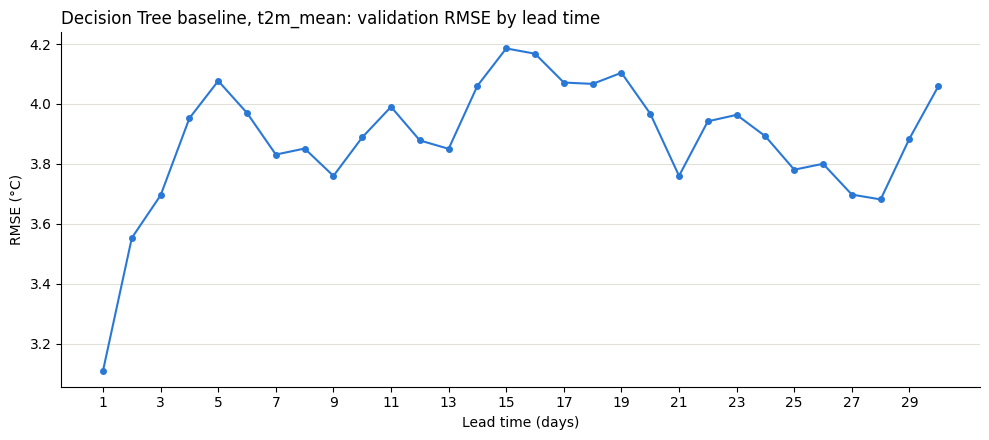

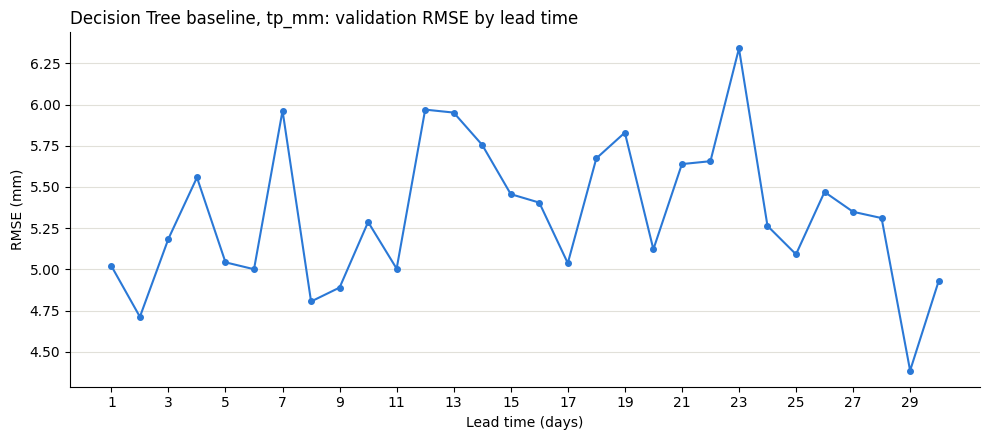

In [6]:
for target, unit, tol in [
    ("t2m_mean", "°C", 2),
    ("tp_mm", "mm", None)
]:
    metrics.plot_rmse(
        y_val[target],
        y_val_pred[target],
        f"Decision Tree baseline, {target}: validation RMSE by lead time",
        unit
    )

    table = metrics.metrics_table(
        {
            "Train": (y_train[target], y_train_pred[target]),
            "Val": (y_val[target], y_val_pred[target]),
            "Test": (y_test[target], y_test_pred[target])
        },
        tolerance=tol
    )

    display(table.style.format("{:.3f}"))

## PROVIAMO CON SCALING E REGOLARIZZAZIONE

In [19]:
from sklearn.preprocessing import StandardScaler

target_scales = y_train.std(axis=0, ddof=0)

In [25]:
def evaluate_tree(max_depth, min_samples_leaf, scale_targets):

    # Optional target standardization
    if scale_targets:
        scaler = StandardScaler()
        Y_fit = scaler.fit_transform(y_train.to_numpy())
    else:
        scaler = None
        Y_fit = y_train.to_numpy()

    # Train model
    model = DecisionTreeRegressor(
        criterion="squared_error",
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        random_state=42
    )

    model.fit(X_train, Y_fit)

    y_pred = model.predict(X_val)

    if scaler is not None:
        y_pred = scaler.inverse_transform(y_pred)

    y_pred = pd.DataFrame(
        y_pred,
        index=y_val.index,
        columns=y_val.columns
    )

    # Normalized MAE: equal importance to all 60 outputs
    errors = (y_val - y_pred).abs()
    normalized_mae = errors.div(target_scales, axis=1).to_numpy().mean()

    temp_mae = metrics.get_mean_absolute_error(
        y_val["t2m_mean"], y_pred["t2m_mean"]
    )

    precip_mae = metrics.get_mean_absolute_error(
        y_val["tp_mm"], y_pred["tp_mm"]
    )

    return {
        "Target scaling": scale_targets,
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "Val normalized MAE": normalized_mae,
        "Val temp MAE": temp_mae,
        "Val precip MAE": precip_mae
    }

In [26]:
results = []

for scale_targets in [False, True]:
    for depth in [5, 10, 20, None]:
        for min_leaf in [1, 10, 50]:

            result = evaluate_tree(
                max_depth=depth,
                min_samples_leaf=min_leaf,
                scale_targets=scale_targets
            )

            results.append(result)

results_df = pd.DataFrame(results)

display(
    results_df
    .sort_values("Val normalized MAE")
    .reset_index(drop=True)
    .round(4)
)

,Target scaling,max_depth,min_samples_leaf,Val normalized MAE,Val temp MAE,Val precip MAE
0,False,5.0,50,0.4213,2.2625,1.9896
1,False,5.0,1,0.4213,2.2625,1.9896
2,False,5.0,10,0.4213,2.2625,1.9896
3,False,10.0,50,0.4223,2.2723,1.9927
4,False,NaN,50,0.4229,2.2900,1.9884
5,False,20.0,50,0.4229,2.2900,1.9884
6,True,5.0,1,0.4252,2.3017,1.9999
7,True,5.0,10,0.4259,2.3004,2.0049
8,True,5.0,50,0.4262,2.3142,2.0007
9,True,10.0,50,0.4300,2.3236,2.0237


NOTE: Scaling doesn't help much

## A MORE THOROUGH HYPERPARAMETER SEARCH

In [27]:
from itertools import product

def evaluate_tree_config(max_depth, min_samples_leaf, max_features):

    model = DecisionTreeRegressor(
        criterion="squared_error",
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_pred = pd.DataFrame(
        model.predict(X_val),
        index=y_val.index,
        columns=y_val.columns
    )

    normalized_mae = (
        (y_val - y_pred).abs()
        .div(target_scales, axis=1)
        .to_numpy()
        .mean()
    )

    return {
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "max_features": str(max_features),
        "Val normalized MAE": normalized_mae,
        "Val temp MAE": metrics.get_mean_absolute_error(
            y_val["t2m_mean"], y_pred["t2m_mean"]
        ),
        "Val precip MAE": metrics.get_mean_absolute_error(
            y_val["tp_mm"], y_pred["tp_mm"]
        ),
        "Tree depth": model.get_depth(),
        "Leaves": model.get_n_leaves()
    }

In [28]:
depths = [3, 4, 5, 6, 7, 8, 10]
min_leaves = [10, 25, 50, 100]
max_features_options = [None, 0.5, "sqrt"]

results = []

for depth, min_leaf, max_features in product(
    depths, min_leaves, max_features_options
):
    results.append(
        evaluate_tree_config(depth, min_leaf, max_features)
    )

results_df = pd.DataFrame(results)

display(
    results_df.sort_values("Val normalized MAE")
    .reset_index(drop=True)
    .round(4)
)

,max_depth,min_samples_leaf,max_features,Val normalized MAE,Val temp MAE,Val precip MAE,Tree depth,Leaves
0,8,100,0.5,0.4179,2.2063,1.9915,8,73
1,8,50,None,0.4200,2.2635,1.9801,8,120
2,6,100,0.5,0.4201,2.2151,2.0038,6,48
3,10,100,0.5,0.4205,2.1911,2.0175,10,79
4,8,100,None,0.4205,2.2309,1.9991,8,73
...,...,...,...,...,...,...,...,...
79,3,50,0.5,0.4377,2.4971,1.9977,3,8
80,3,100,0.5,0.4377,2.4971,1.9977,3,8
81,3,10,0.5,0.4377,2.4971,1.9977,3,8
82,10,10,None,0.4405,2.3926,2.0674,10,430


## OPTUNA

In [10]:
import optuna

target_scales = y_train.std(axis=0, ddof=0).replace(0, 1)


def objective(trial):

    max_depth = trial.suggest_int(
        "max_depth", 3, 15
    )

    min_samples_leaf = trial.suggest_int(
        "min_samples_leaf", 20, 200, log=True
    )

    min_samples_split = trial.suggest_int(
        "min_samples_split",
        2 * min_samples_leaf,
        600
    )

    max_features = trial.suggest_categorical(
        "max_features",
        [None, "sqrt", "log2", 0.3, 0.5, 0.7, 0.9]
    )

    #High means low complexity of the tree and low mmeans high complexity
    ccp_alpha = trial.suggest_categorical(
        "ccp_alpha",
        [0.0, 1e-5, 1e-4, 1e-3, 1e-2, 0.1]
    )

    model = DecisionTreeRegressor(
        criterion="squared_error",
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        ccp_alpha=ccp_alpha,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)

    normalized_mae = (
        np.abs(y_val.to_numpy() - y_pred)
        / target_scales.to_numpy()
    ).mean()

    return normalized_mae


sampler = optuna.samplers.TPESampler(seed=42)

study = optuna.create_study(
    direction="minimize",
    sampler=sampler
)

study.optimize(
    objective,
    n_trials=100,
    show_progress_bar=True
)

print("Best validation normalized MAE:", study.best_value)
print("Best hyperparameters:", study.best_params)

[I 2026-11-24 10:59:03,557] A new study created in memory with name: no-name-2c872d63-a6fb-4ce0-9127-c94fc93ae7fe


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-11-24 10:59:04,015] Trial 0 finished with value: 0.42112522460361695 and parameters: {'max_depth': 7, 'min_samples_leaf': 179, 'min_samples_split': 535, 'max_features': 0.5, 'ccp_alpha': 1e-05}. Best is trial 0 with value: 0.42112522460361695.
[I 2026-11-24 10:59:04,664] Trial 1 finished with value: 0.41871521099173764 and parameters: {'max_depth': 6, 'min_samples_leaf': 66, 'min_samples_split': 334, 'max_features': 0.9, 'ccp_alpha': 0.01}. Best is trial 1 with value: 0.41871521099173764.
[I 2026-11-24 10:59:05,175] Trial 2 finished with value: 0.435284760890653 and parameters: {'max_depth': 3, 'min_samples_leaf': 178, 'min_samples_split': 592, 'max_features': None, 'ccp_alpha': 1e-05}. Best is trial 1 with value: 0.41871521099173764.
[I 2026-11-24 10:59:05,387] Trial 3 finished with value: 0.4300839090989289 and parameters: {'max_depth': 10, 'min_samples_leaf': 30, 'min_samples_split': 584, 'max_features': 'sqrt', 'ccp_alpha': 0.01}. Best is trial 1 with value: 0.4187152109917

In [11]:
trials_df = study.trials_dataframe()

display(
    trials_df.sort_values("value")
    [["number", "value"]]
    .head(10)
)

,number,value
20,20,0.415080
90,90,0.416025
92,92,0.416278
6,6,0.416366
63,63,0.416376
64,64,0.416415
88,88,0.416417
41,41,0.416590
59,59,0.416636
77,77,0.417135


## TESTING

In [12]:
best_params = study.best_params

print("Selected hyperparameters:")
print(best_params)

# Train final model
joint = DecisionTreeRegressor(
    criterion="squared_error",
    random_state=42,
    **best_params
)

joint.fit(X_train, y_train)

print(f"\nTree depth: {joint.get_depth()}")
print(f"Number of leaves: {joint.get_n_leaves()}")

Selected hyperparameters:
{'max_depth': 9, 'min_samples_leaf': 66, 'min_samples_split': 272, 'max_features': 0.7, 'ccp_alpha': 0.0}

Tree depth: 9
Number of leaves: 60


In [13]:
y_train_pred = predict_df(joint, X_train, y_train)
y_val_pred   = predict_df(joint, X_val, y_val)
y_test_pred  = predict_df(joint, X_test, y_test)

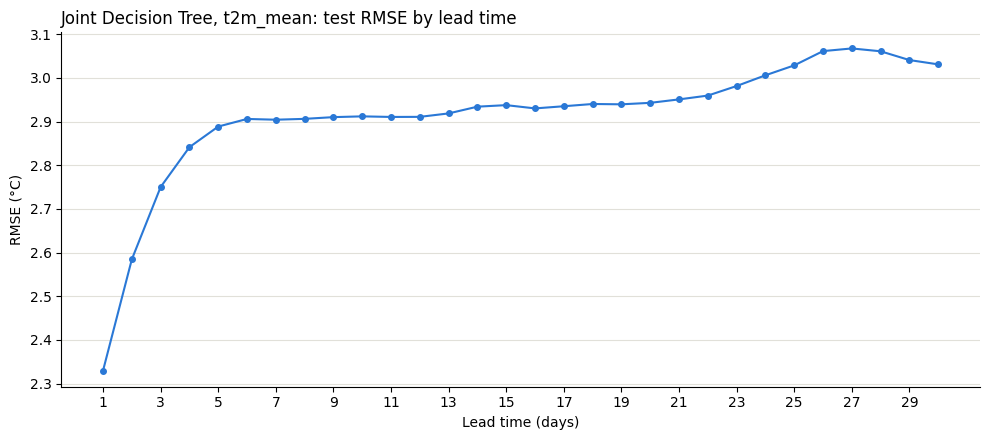

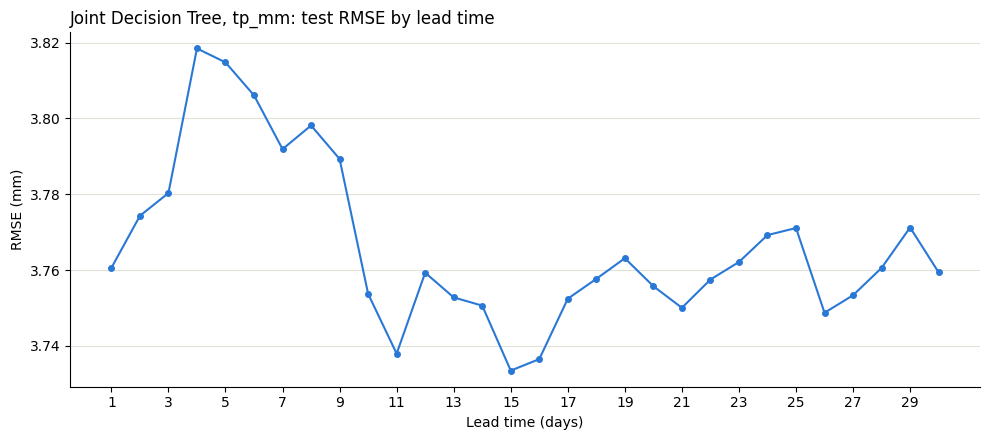

In [14]:
for target, unit, tol in [
    ("t2m_mean", "°C", 2),
    ("tp_mm", "mm", None)
]:
    metrics.plot_rmse(
        y_test[target],
        y_test_pred[target],
        f"Joint Decision Tree, {target}: test RMSE by lead time",
        unit
    )

    table = metrics.metrics_table(
        {
            "Train": (y_train[target], y_train_pred[target]),
            "Val":   (y_val[target], y_val_pred[target]),
            "Test":  (y_test[target], y_test_pred[target])
        },
        tolerance=tol
    )

    display(table.style.format("{:.3f}"))

NOTE: The model does good on temperatures but on precipitations it doesn't learn the undelying pattern (if it exists).